In [53]:
import matplotlib.pyplot as plt
import os.path
import glob
import json

In [100]:
METRICS_PATH = "/media/joe/slepnir1/Datasets/ALSSA/VanDam-5minute/VTC-inferred/metrics"


In [109]:
# The code in this cell extracts each file's metrics and then lets the caller select a specific metric
# from each file.  This can then be used to calculate statistics, plot metric values, or whatever.
def get_all_metrics_from_folder(metrics_pth):
    for pth in glob.glob(os.path.join(METRICS_PATH, "**/*.json")):
        with open(pth, "r") as fd:
            obj = json.load(fd)
            #print (obj)
            yield obj

def get_metric_from_summary(obj, metric_name):
    #print (obj)
    for k,v in obj.items():
        yield k, v[metric_name]["value"]

def collect_metrics(pth, metric_name):
    return {k: v for obj in get_all_metrics_from_folder(METRICS_PATH) for (k,v) in get_metric_from_summary(obj, metric_name)}


#example usage
#-----------------------------------------------------------------------------------
#metric_name = "DiarizationErrorRate"
#metrics = collect_metrics(METRICS_PATH, metric_name)
#metrics
# or...
#files, ders = zip(*metrics.items())
#print(ders)

# to keep metrics in memory for multiple query..
#objs = {k:v for o in get_all_metrics_from_folder(METRICS_PATH) for (k,v) in o.items()}
#der_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(objs, "DiarizationErrorRate")}
#id_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(objs, "IdentificationPrecision")}
#print(der_metrics)
#print(id_metrics)

In [205]:
#extract all recorded metrics' identifiers.  These are the types of metrics that were recorded.
def get_metric_identifiers(obj):
    for k,v in obj.items():
        yield k

# usage example
metric_objs = {k:v for o in get_all_metrics_from_folder(METRICS_PATH) for (k,v) in o.items()}
#print(metric_objs)
it = iter(metric_objs.items())
obj = next(it)[1]
print(list(get_metric_identifiers(obj)))

['DiarizationErrorRate', 'DiarizationCoverage', 'DiarizationPurity', 'SegmentationCoverage', 'SegmentationPurity', 'DetectionPrecisionRecallFMeasure', 'SegmentationPurityCoverageFMeasure', 'IdentificationPrecision', 'IdentificationRecall']


In [206]:
# draw some bar charts
def draw_charts(title, metrics):
    def draw_subplot(ax, sp_title, xs, ys, avg_value, median_value):
        ax.margins(x=0) #take up all the space
        ax.set_title(sp_title, fontsize=18)
        ax.tick_params(axis='x', labelrotation=90, labelsize=6)
        ax.grid()
        ax.bar(xs, ys)
        ax.axhline(avg_value, color='r')
        ax.axhline(median_value, color='g')
        return ax
        
    files, values =  zip(*metrics.items()) #separate for drawing

    avg_value = statistics.mean(values)
    median_value = statistics.median(values)

    # sort by metric values
    sorted_metrics = dict(sorted(metrics.items(), key= lambda x: x[1]))
    sorted_files, sorted_values = zip(*sorted_metrics.items())

    #set up plots
    fig, (ax1, ax2) = plt.subplots(2,1, figsize=(25, 15))
    fig.suptitle(title, fontsize=24)

    # draw the subplots
    draw_subplot(ax1, 'By File Name', files, values, avg_value, median_value)
    draw_subplot(ax2, 'By Score', sorted_files, sorted_values, avg_value, median_value)

    fig.tight_layout()



In [207]:
# ok, now get the metrics into a dictionary
metric_objs = {k:v for o in get_all_metrics_from_folder(METRICS_PATH) for (k,v) in o.items()}

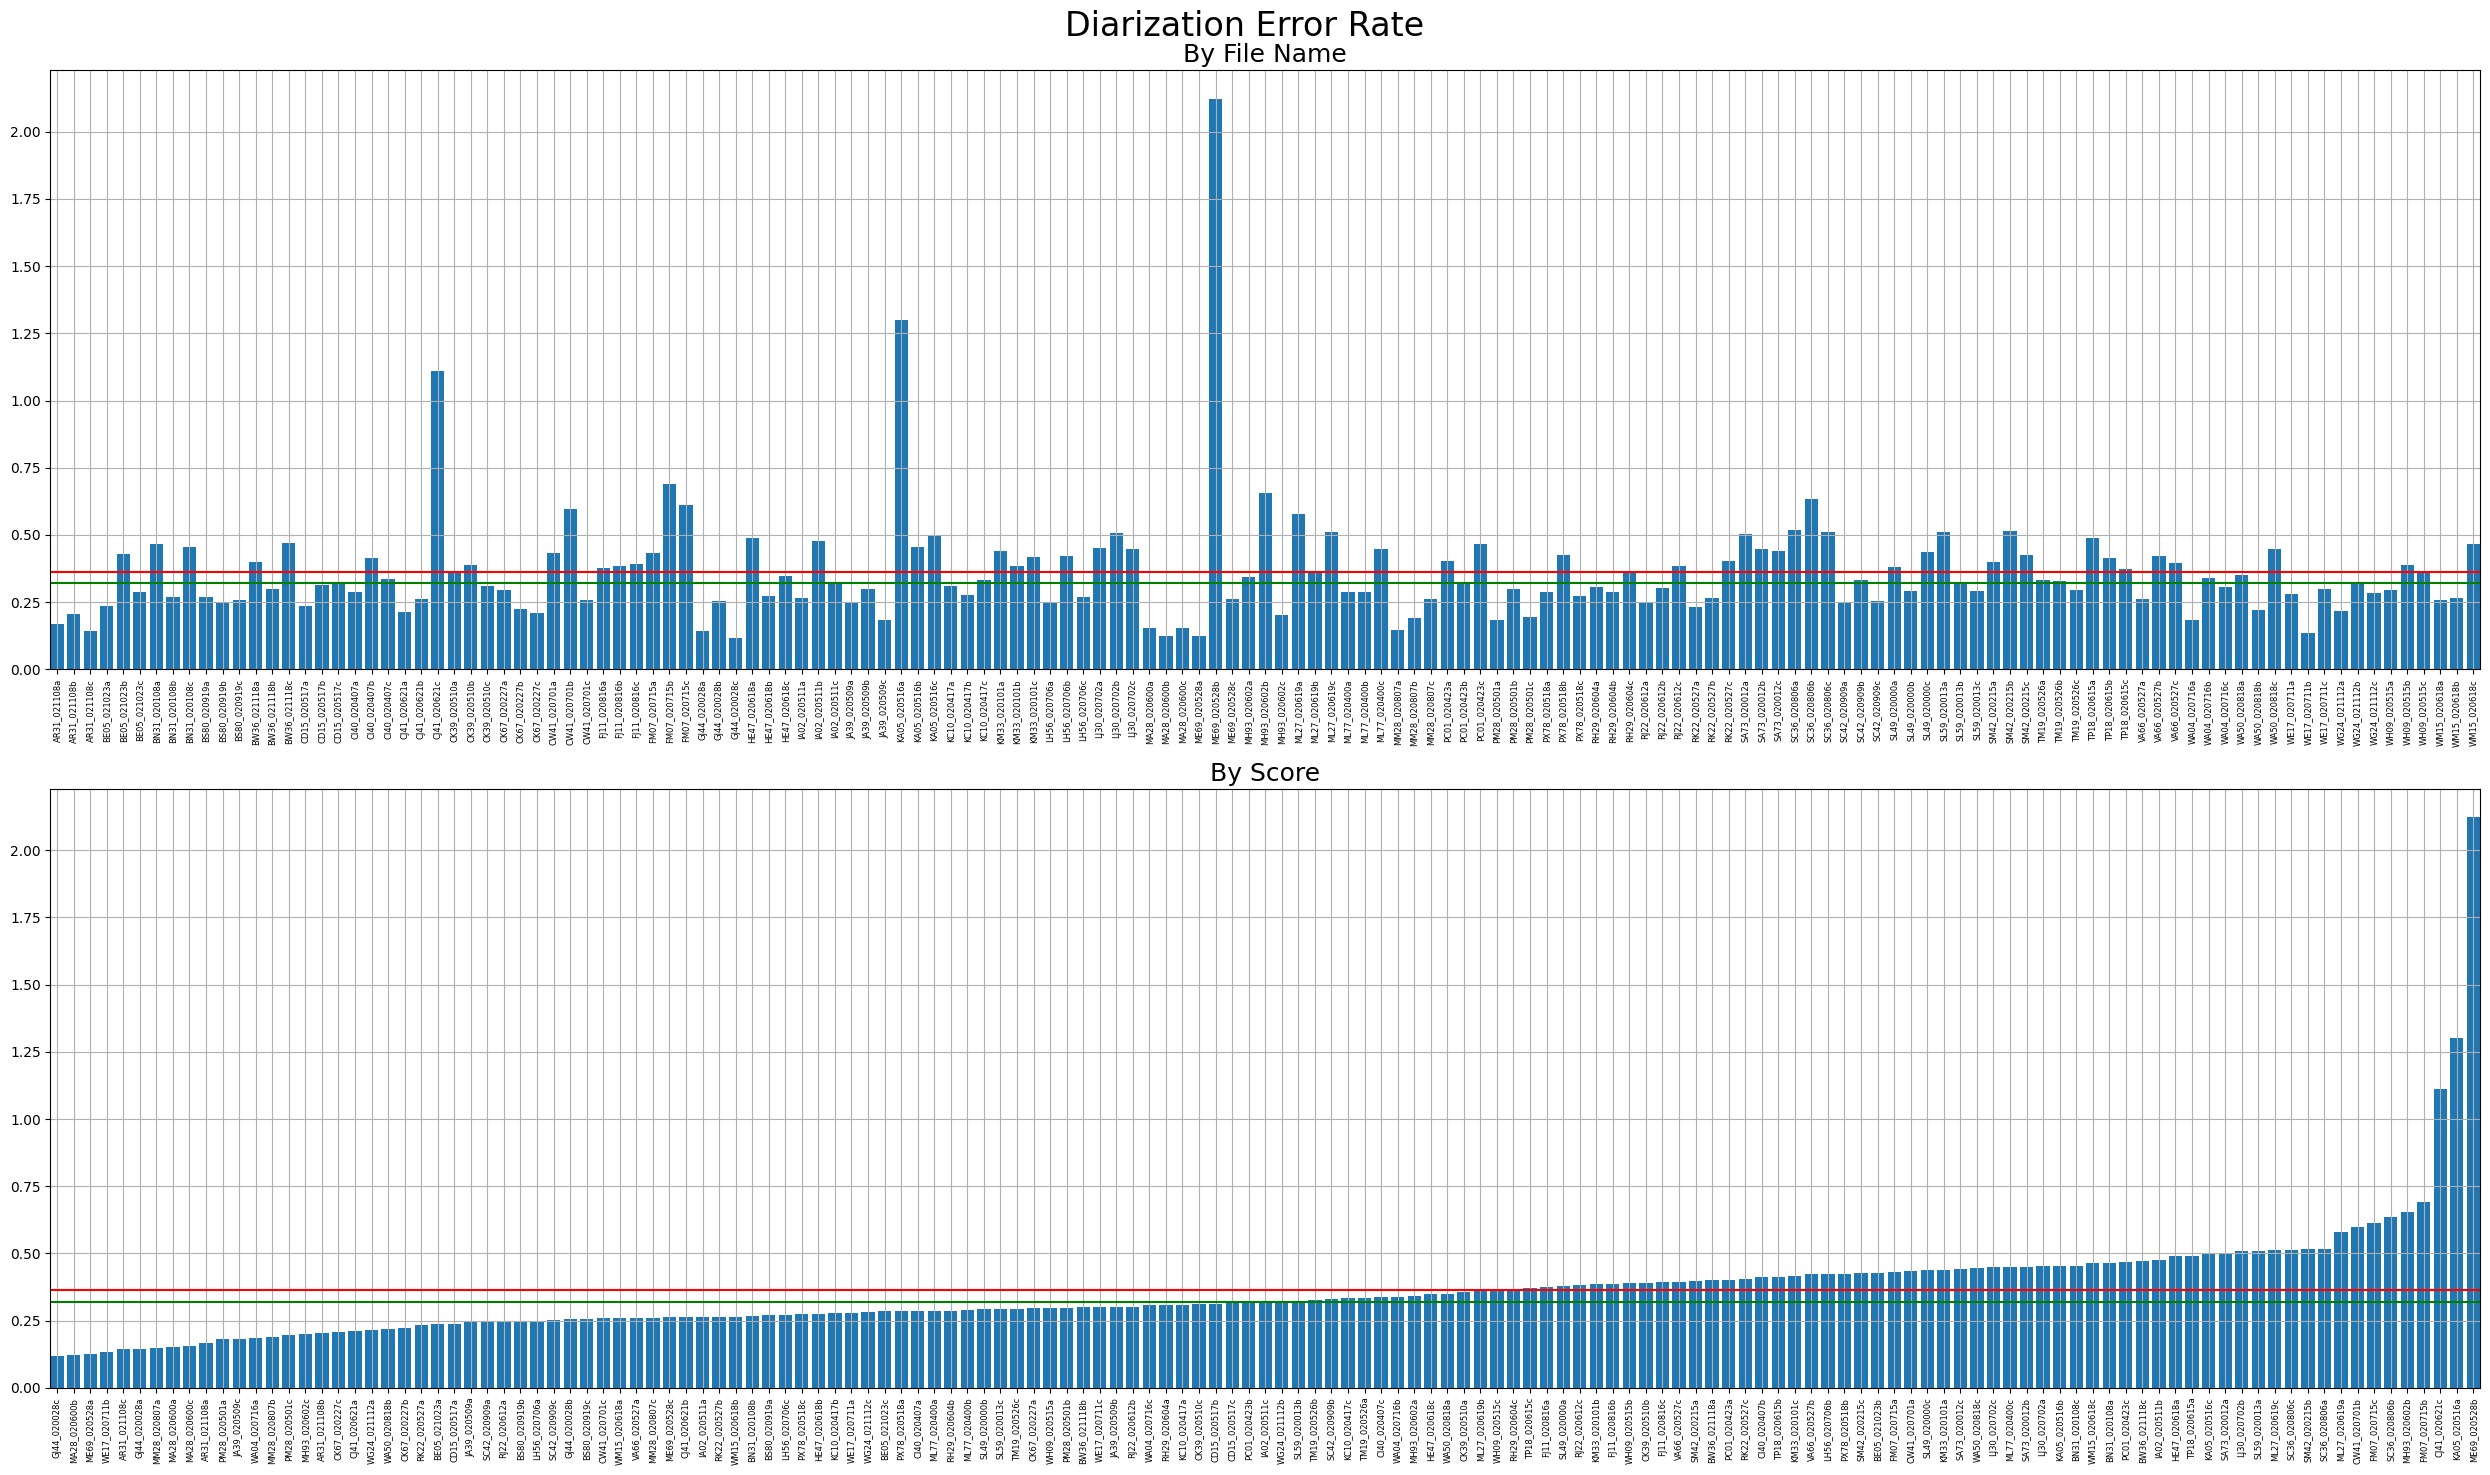

In [208]:
import statistics

# diagram diarization error rates for each file
der_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(metric_objs, "DiarizationErrorRate")}
der_metrics = dict(sorted(der_metrics.items(), key= lambda x:x[0]))
draw_charts('Diarization Error Rate', der_metrics)

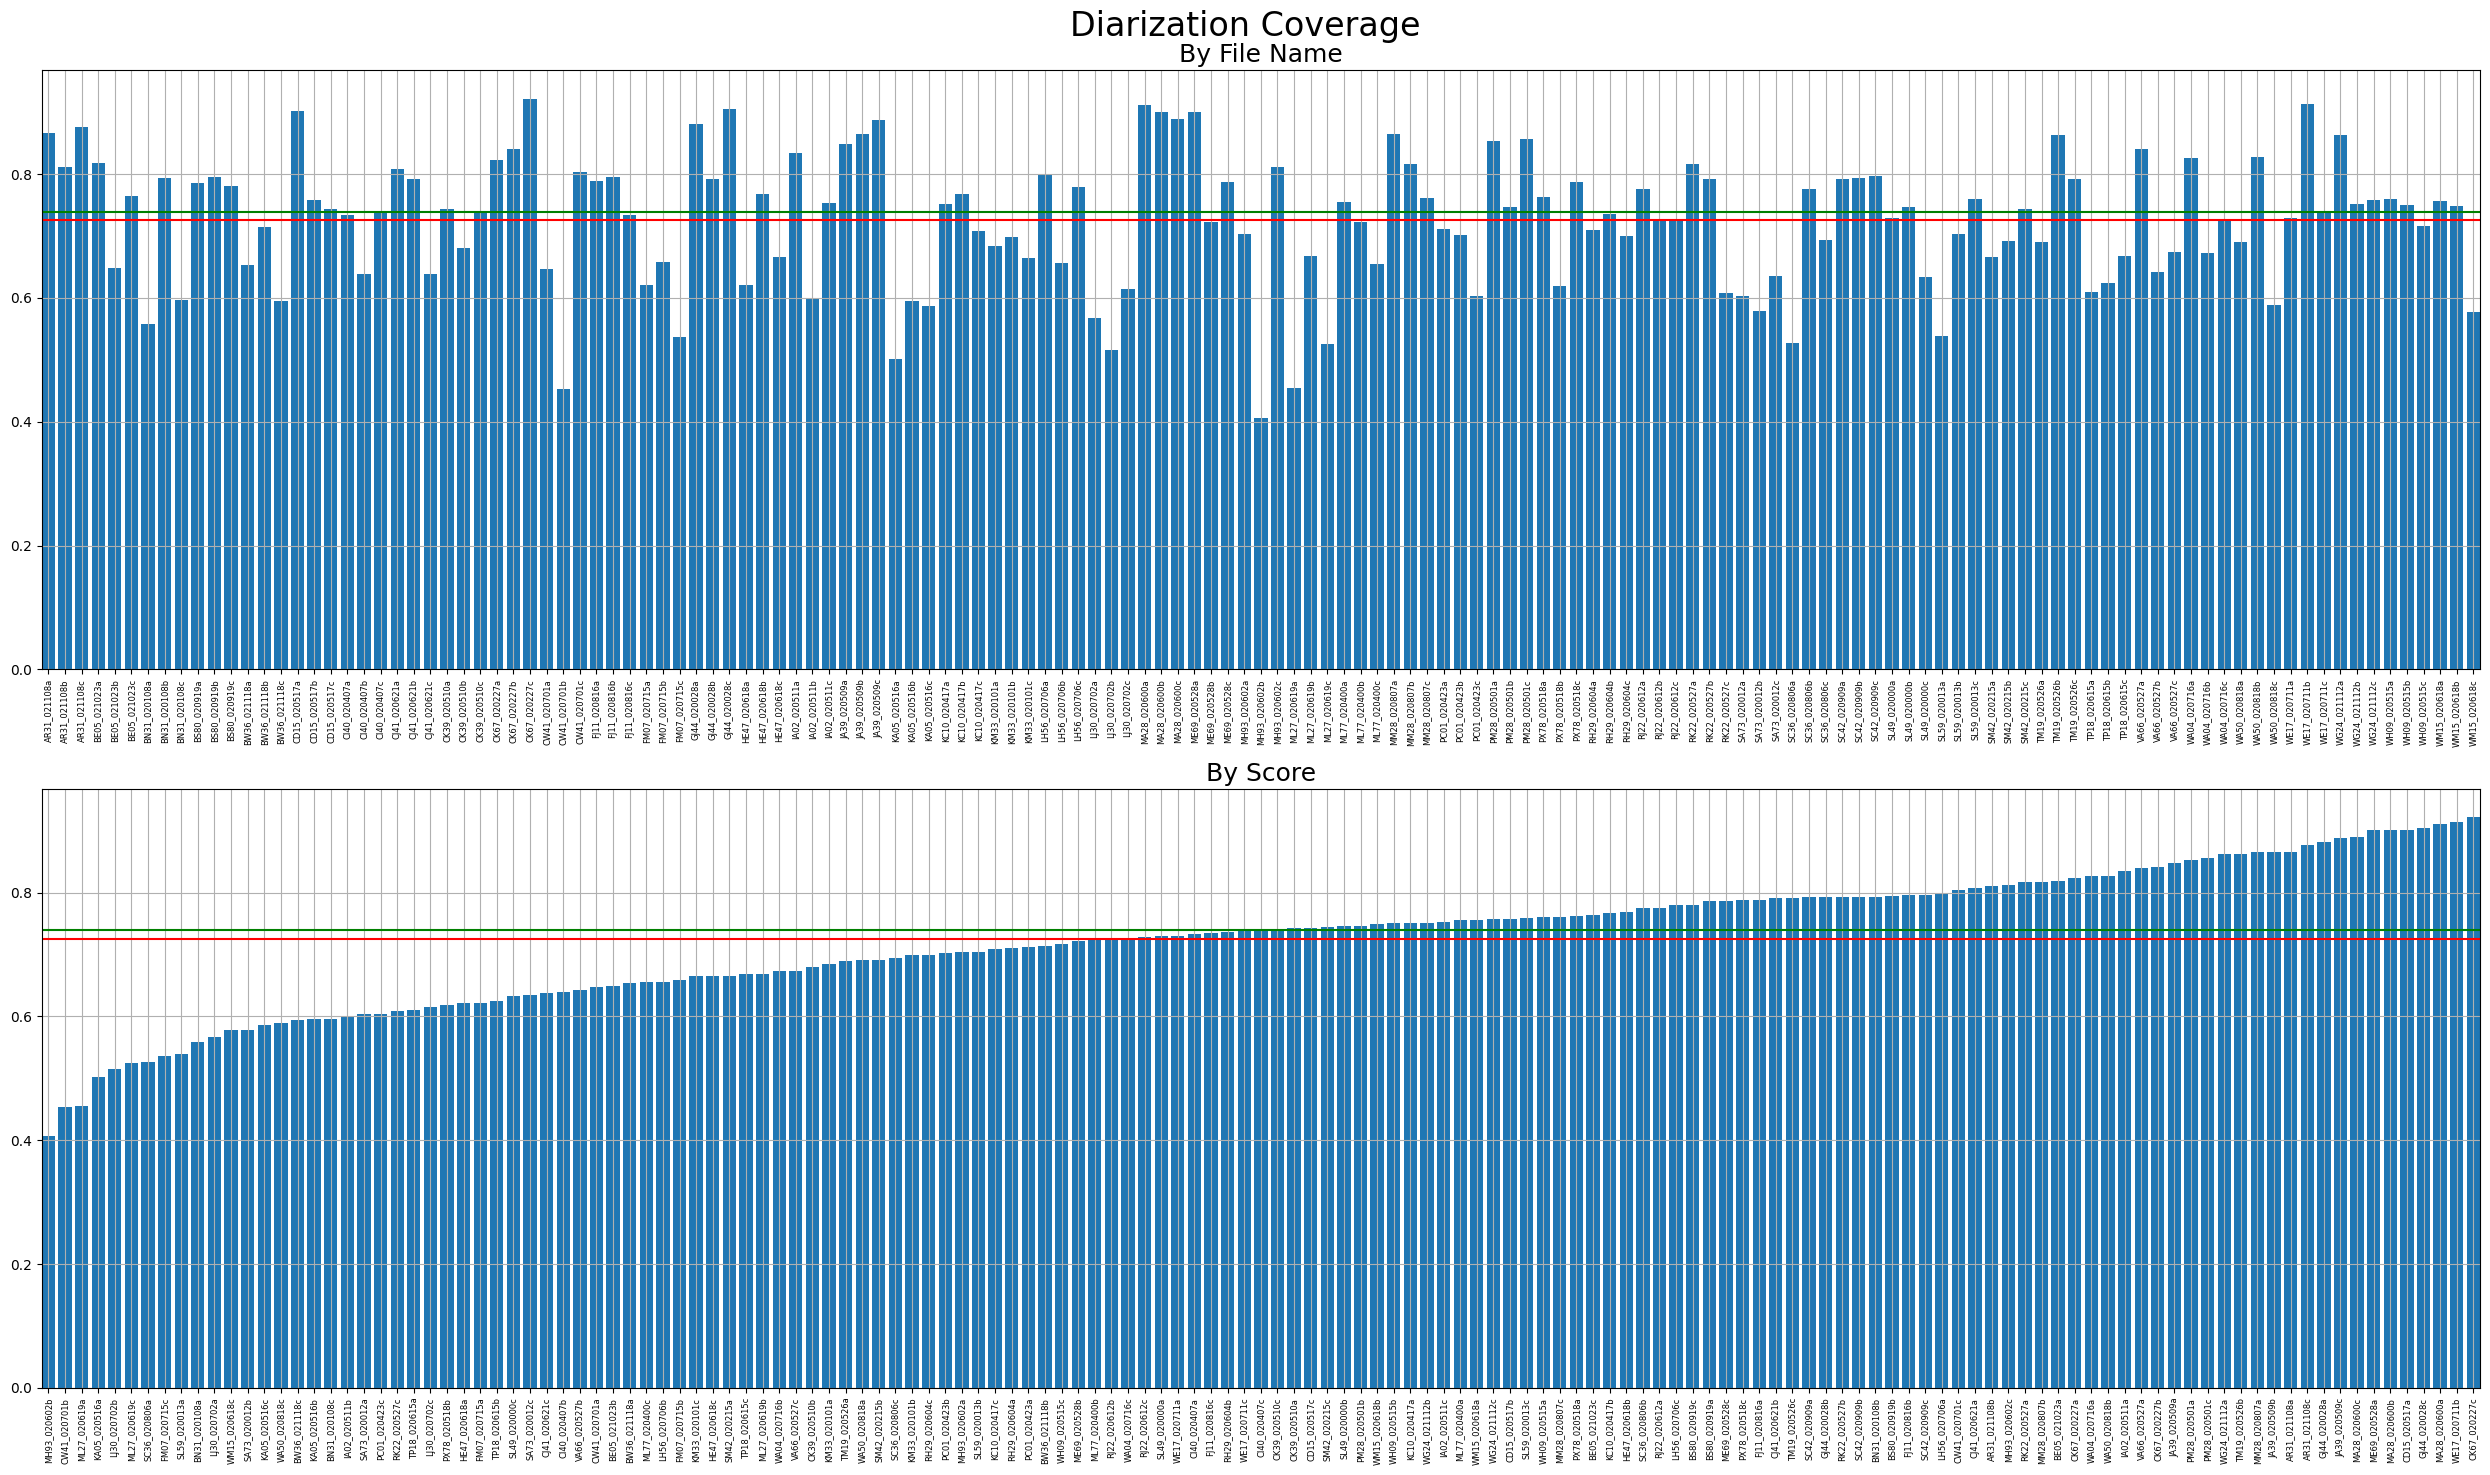

In [209]:
# diagram diarization Coverage for each file
dc_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(metric_objs, "DiarizationCoverage")}
dc_metrics = dict(sorted(dc_metrics.items(), key= lambda x:x[0]))
draw_charts('Diarization Coverage', dc_metrics)


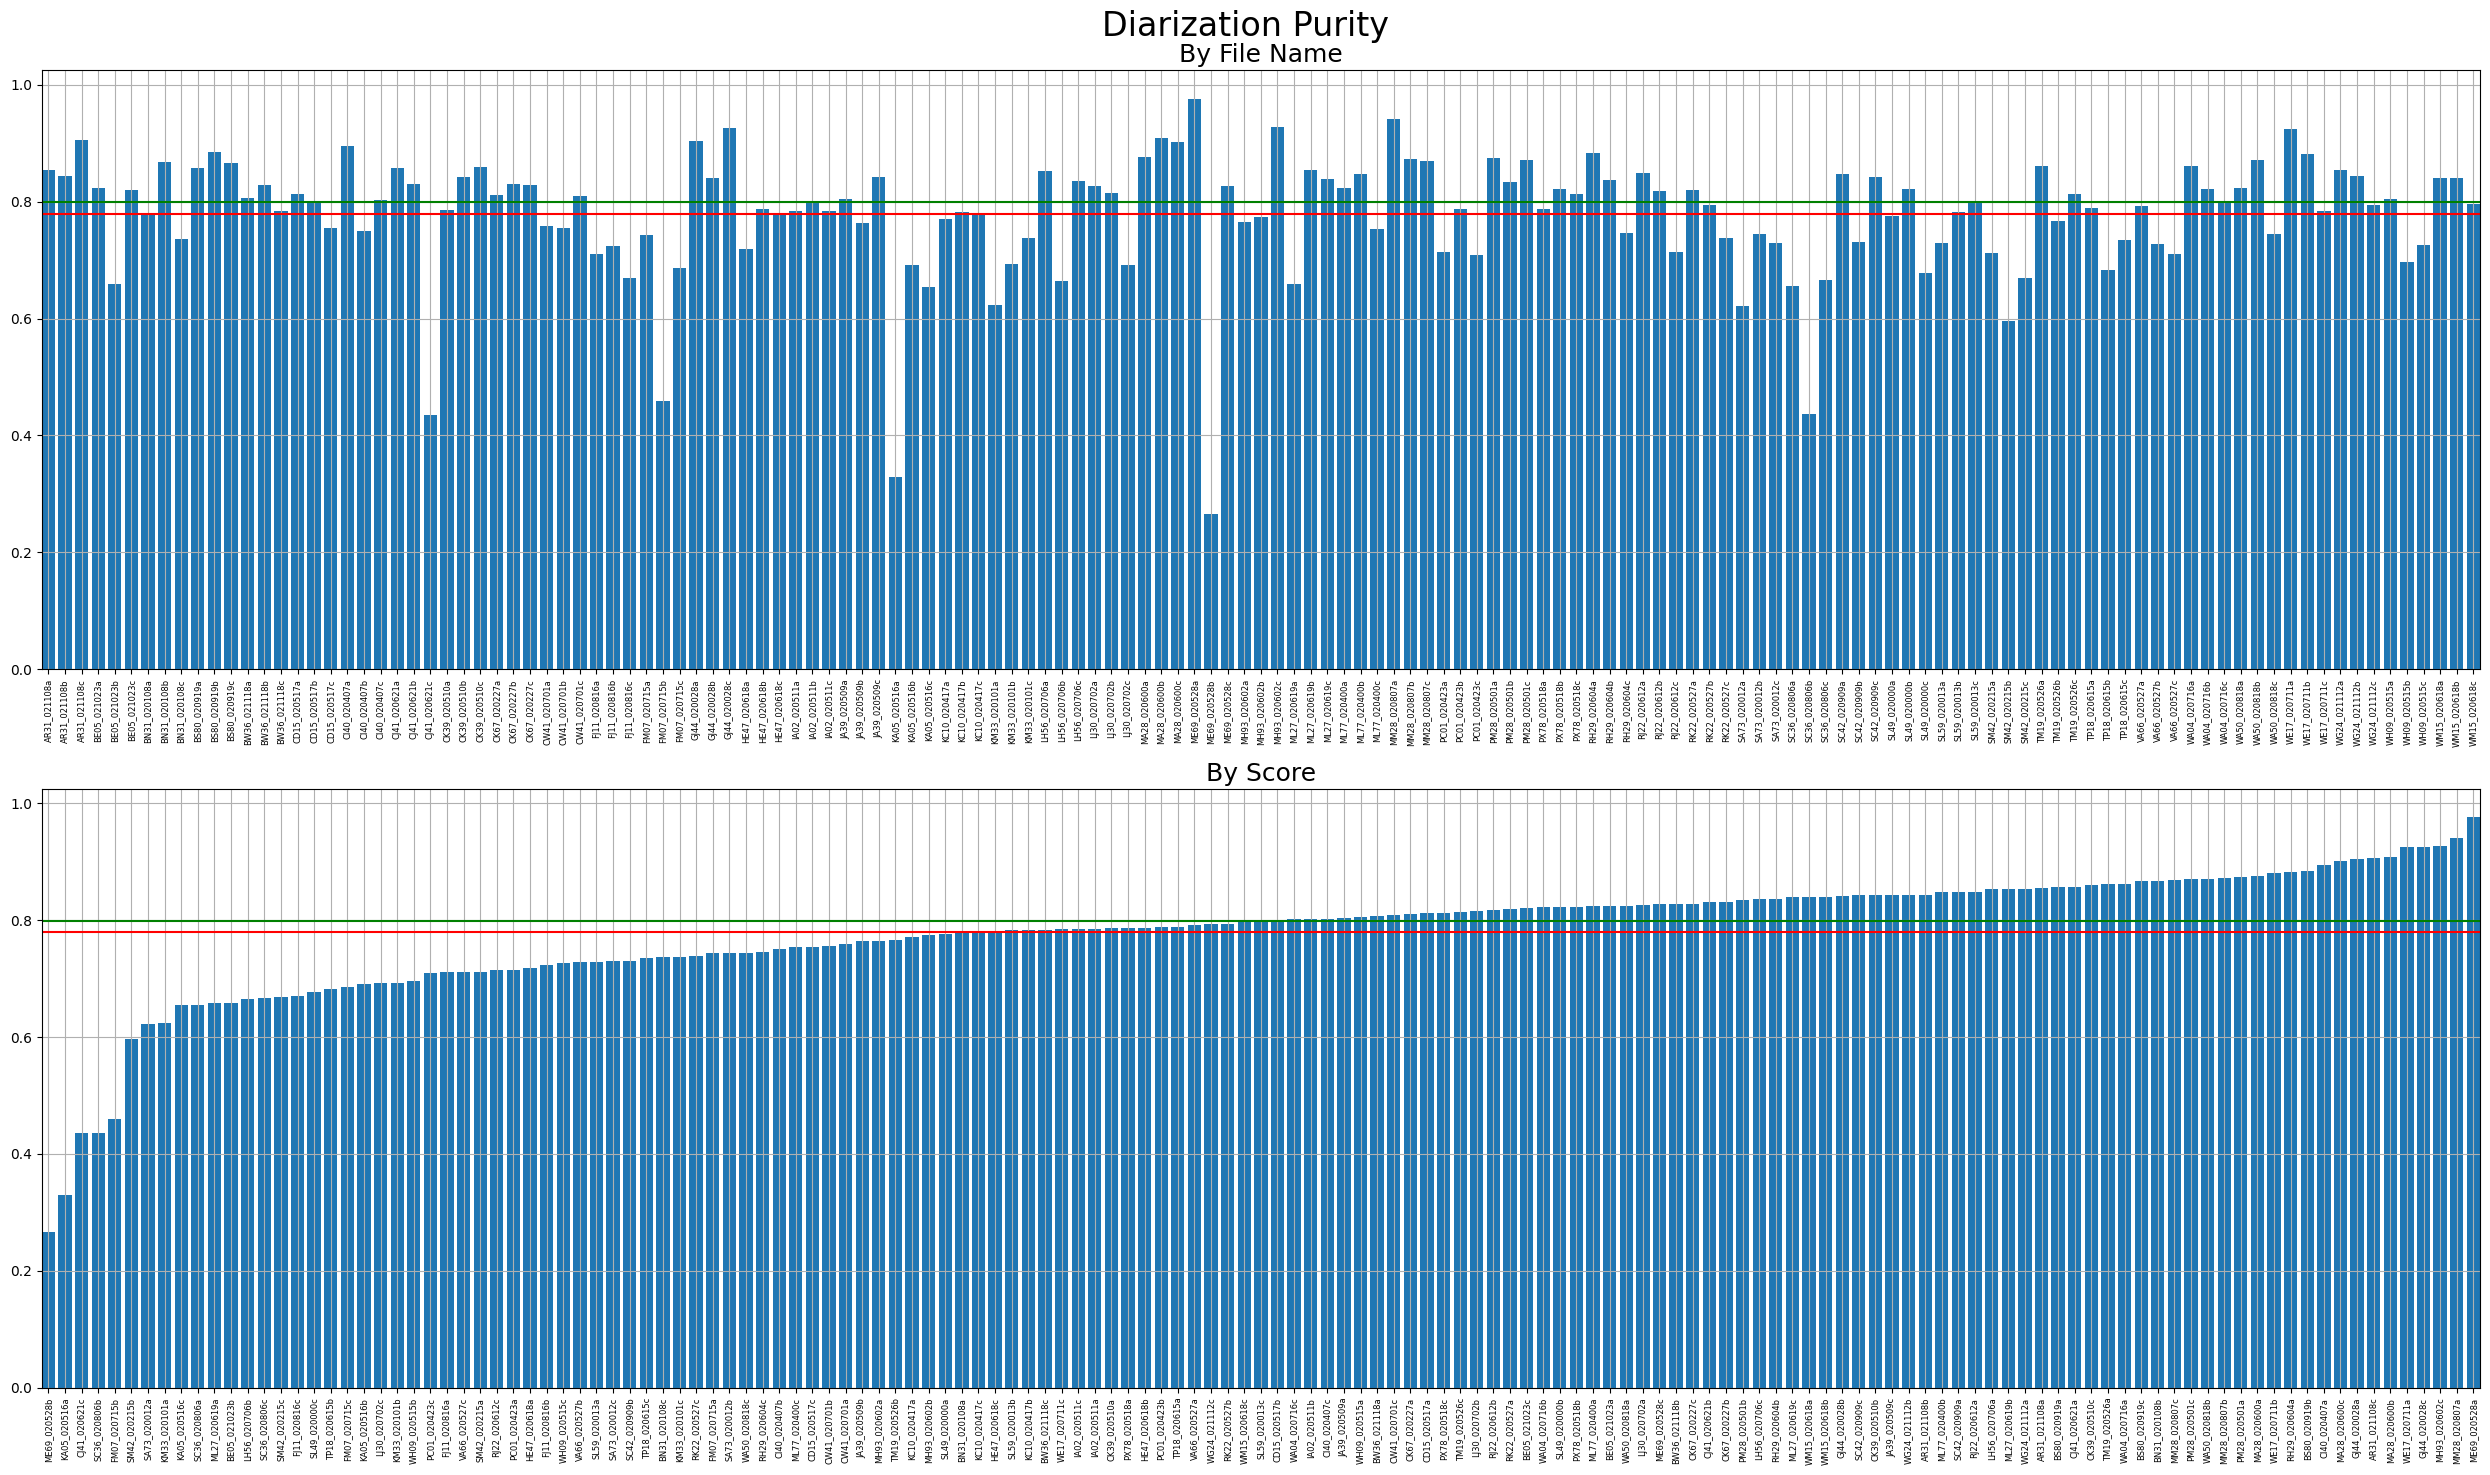

In [210]:
# diagram Diarization Purity for each file
dp_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(metric_objs, "DiarizationPurity")}
dp_metrics = dict(sorted(dp_metrics.items(), key= lambda x:x[0]))
draw_charts('Diarization Purity', dp_metrics)


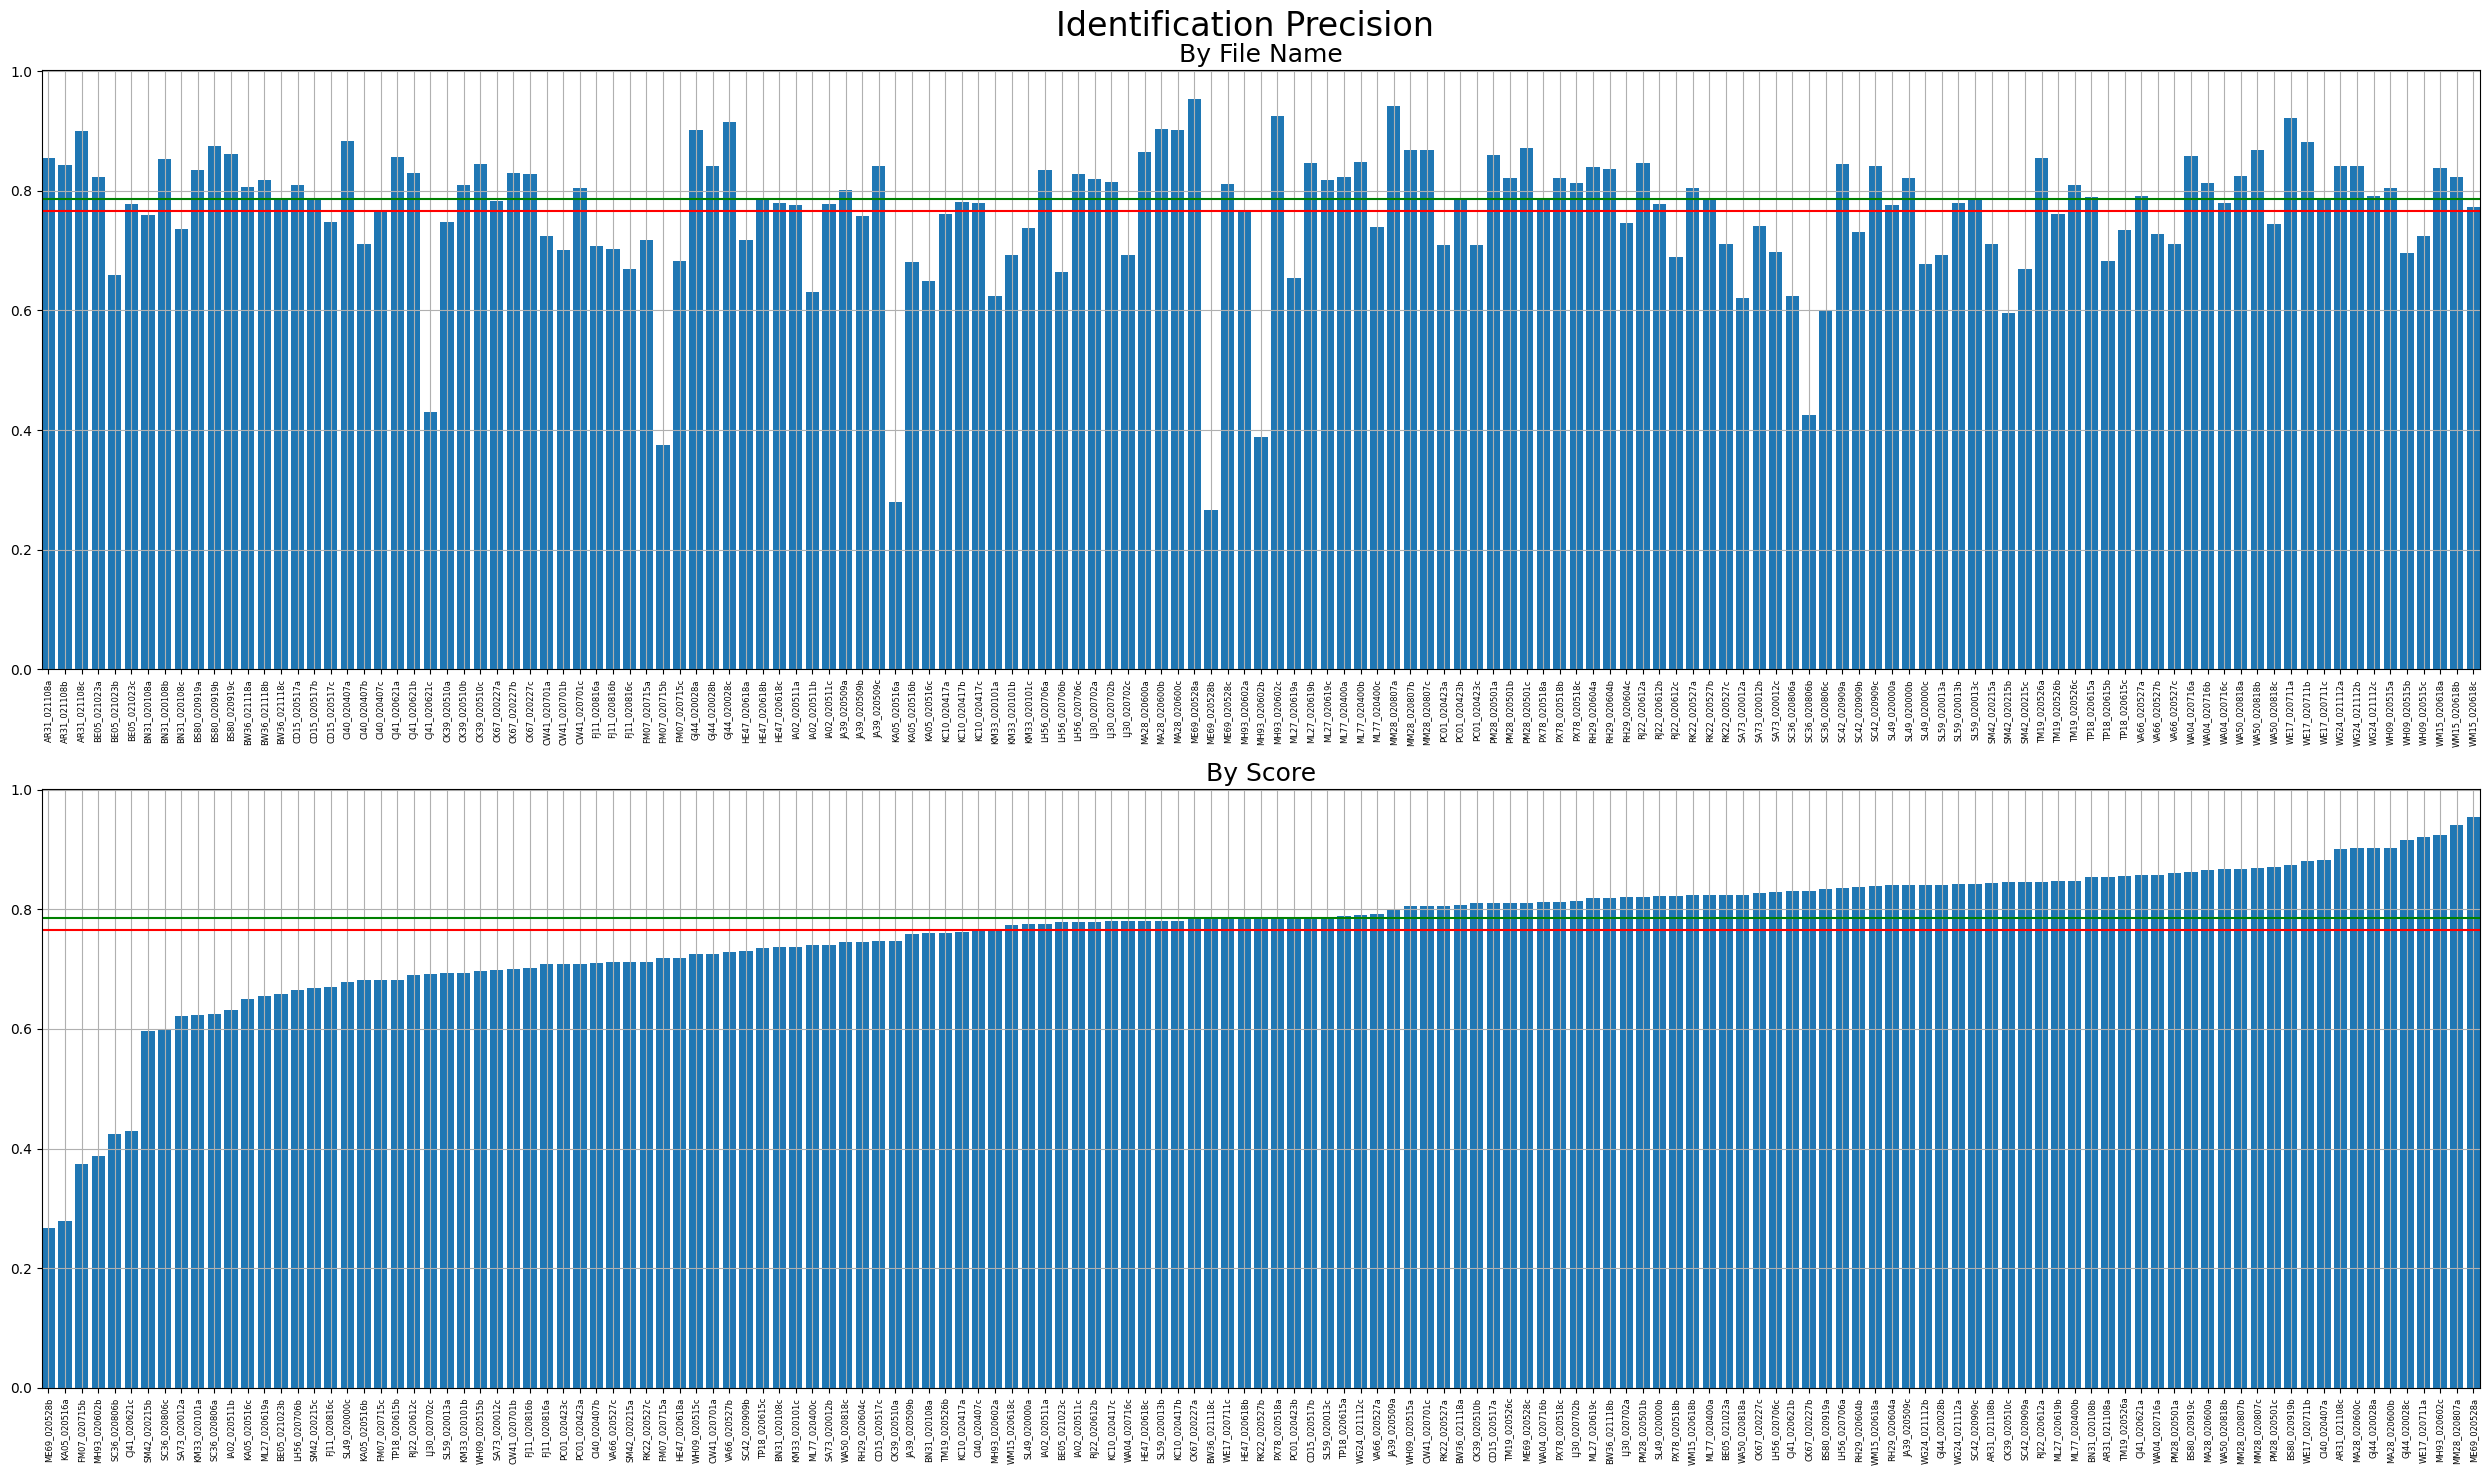

In [211]:
# plot Identification Precision
ip_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(metric_objs, "IdentificationPrecision")}
ip_metrics = dict(sorted(ip_metrics.items(), key= lambda x:x[0]))
draw_charts('Identification Precision', ip_metrics)


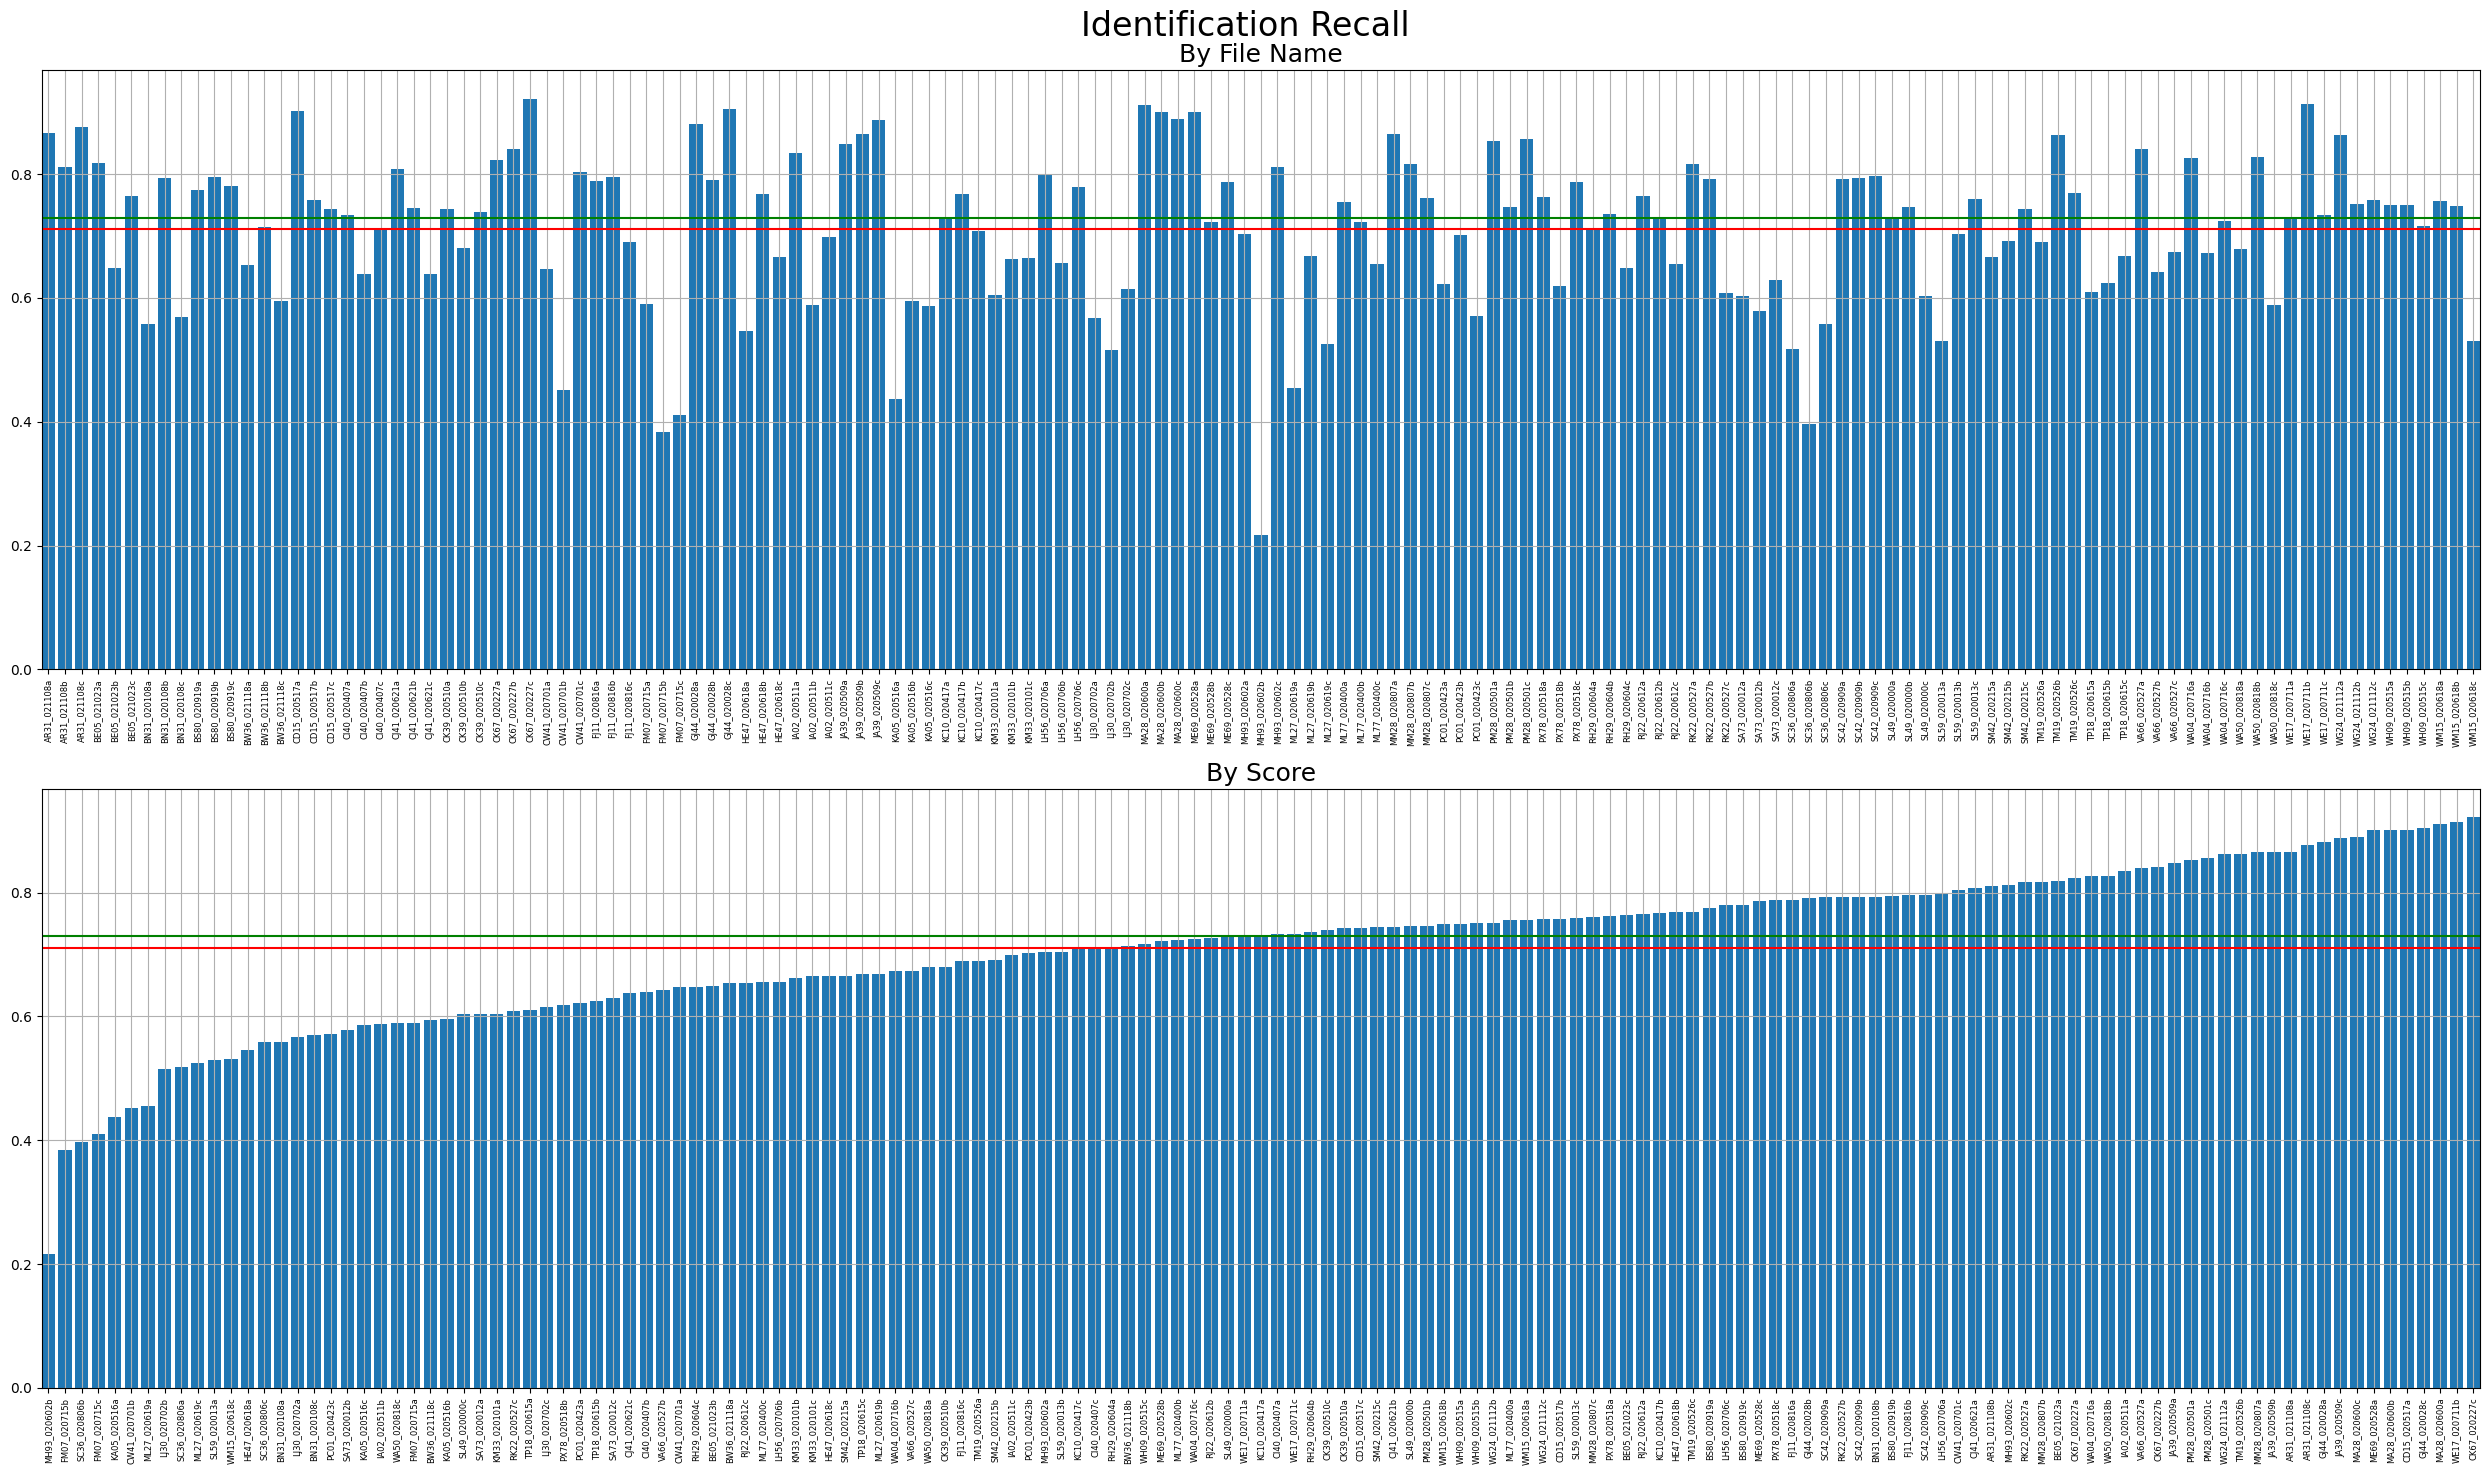

In [212]:
# plot Identification Recall
ir_metrics = {k: v for o in objs for (k,v) in get_metric_from_summary(metric_objs, "IdentificationRecall")}
ir_metrics = dict(sorted(ir_metrics.items(), key= lambda x:x[0]))
draw_charts('Identification Recall', ir_metrics)
